# Immuno Compass · Notebook 03: Exploratory data analysis (Day 3)

**Goal:** look at the clean cohort table with charts *before* modelling, so we know what the models should find
and which traps to avoid.

**Finish line:** we can answer
1. What do ADA frequencies look like? (Is there a spike at 0 %?)
2. Is the data noisier than simple coin-flipping predicts? (**overdispersion**)
3. Which routes, diseases, drug types, doses… have higher ADA?
4. Do a handful of drugs dominate the data?

> 🧒 *Simple version:* before building a guessing machine, we draw pictures to see the patterns with our own eyes.

### Three ways to summarise "ADA % of a group" (we show all three)
| Summary | How | Weakness |
|---|---|---|
| **Pooled** | all ADA+ patients ÷ all patients tested | Big trials dominate |
| **Mean of cohorts** | average of each cohort's % | Tiny noisy cohorts count as much as huge ones |
| **Drug-balanced** | pooled % per drug, then average over drugs | Each drug counts once, so one popular drug can't dominate |

**Uncertainty:** cohorts of the same drug are not independent, so we compute 95 % intervals by a
**drug-level bootstrap**: re-draw *drugs* (not cohorts) at random 1,000 times and see how much the pooled % moves.

## 0 · Setup

In [1]:
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

np.random.seed(42)
pd.set_option("display.max_columns", 60)

CANDIDATES = [Path("data/processed"), Path("../data/processed"), Path("/content/immuno-compass/data/processed"), Path("/content/data/processed")]
PROC = next((p for p in CANDIDATES if (p / "cohorts.csv").exists()), None)
if PROC is None and "google.colab" in sys.modules:
    from google.colab import files
    PROC = Path("/content/data/processed"); PROC.mkdir(parents=True, exist_ok=True)
    print("Please upload cohorts.csv (made by notebook 02)")
    for name, content in files.upload().items():
        (PROC / name).write_bytes(content)
assert PROC is not None, "Run notebook 02 first (it creates data/processed/cohorts.csv)"
FIG = PROC.parent.parent / "figures"; FIG.mkdir(exist_ok=True)

df = pd.read_csv(PROC / "cohorts.csv")
DRUG = "Therapeutic Assessed for ADA ID"
print(df.shape, "| drugs:", df[DRUG].nunique(), "| patients:", df["n"].sum())

(1754, 38) | drugs: 137 | patients: 211018


In [2]:
# ---- One consistent, colour-blind-safe chart style for the whole project ----
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

## 1 · Helper: the three summaries + drug-level bootstrap interval

In [3]:
def drug_bootstrap_ci(g, B=1000, seed=42):
    """95 % interval for the pooled ADA % by re-sampling DRUGS with replacement."""
    per_drug = g.groupby(DRUG)[["y", "n"]].sum().values           # one (y, n) pair per drug
    if len(per_drug) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(per_drug), size=(B, len(per_drug)))   # B re-draws of the drug list
    ys, ns = per_drug[idx, 0].sum(1), per_drug[idx, 1].sum(1)
    return np.percentile(ys / ns, [2.5, 97.5])

def summarise(data, col, min_cohorts=1):
    rows = []
    for level, g in data.groupby(col, observed=True):
        lo, hi = drug_bootstrap_ci(g)
        per_drug = g.groupby(DRUG)[["y", "n"]].sum()
        rows.append({col: level, "cohorts": len(g), "drugs": g[DRUG].nunique(), "patients": g["n"].sum(),
                     "pooled": g["y"].sum() / g["n"].sum(), "ci_low": lo, "ci_high": hi,
                     "mean_of_cohorts": g["ada_freq"].mean(),
                     "drug_balanced": (per_drug["y"] / per_drug["n"]).mean()})
    out = pd.DataFrame(rows).query("cohorts >= @min_cohorts").sort_values("pooled")
    return out

def show(t):
    pct = ["pooled", "ci_low", "ci_high", "mean_of_cohorts", "drug_balanced"]
    display(t.style.format({c: "{:.1%}" for c in pct} | {"patients": "{:,.0f}"}).hide(axis="index"))

def dot_plot(t, col, title, fname, note=None):
    """Pooled ADA % per group as a dot with its drug-bootstrap 95 % interval; label shows #drugs."""
    fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(t) + 1.3))
    yy = np.arange(len(t))
    ax.hlines(yy, t["ci_low"] * 100, t["ci_high"] * 100, color=BLUE, alpha=0.45, lw=2)
    ax.plot(t["pooled"] * 100, yy, "o", color=BLUE, ms=8, mec="white", mew=1.5)
    ax.axvline(overall * 100, color=GRAY, lw=1, ls="--")
    ax.text(overall * 100, -0.75, f" all cohorts {overall:.0%}", color=INK2, fontsize=8, va="center")
    ax.set_ylim(-1.1, len(t) - 0.5)
    ax.set_yticks(yy, [f"{l}  ({d} drug{'s' if d != 1 else ''})" for l, d in zip(t[col], t["drugs"])])
    ax.set_xlabel("% of patients who made anti-drug antibodies (pooled)")
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.set_xlim(left=0)
    if note: fig.text(0.01, -0.02, note, fontsize=8, color=INK2)
    fig.savefig(FIG / fname); plt.show()

overall = df["y"].sum() / df["n"].sum()
print(f"overall pooled ADA: {overall:.1%} | mean of cohorts: {df['ada_freq'].mean():.1%}")

overall pooled ADA: 12.9% | mean of cohorts: 12.9%


## 2 · What do ADA frequencies look like?

cohorts with exactly 0 % ADA: 34.7%
…and how that depends on cohort size (small cohorts hit 0 % by chance much more often):


,cohorts,share_zero
n,,
1–10,388,68%
11–20,200,53%
21–50,356,40%
51–100,278,18%
101–500,463,10%
>500,69,3%


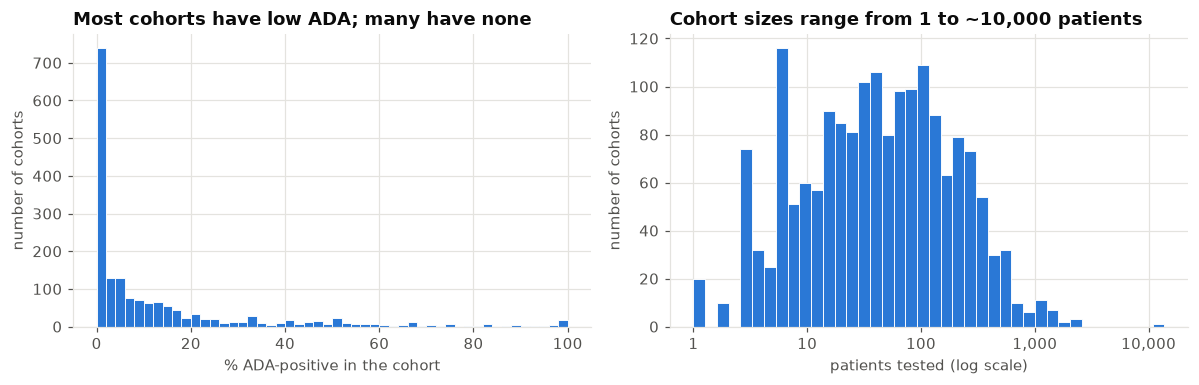

In [4]:
zero = df["ada_freq"].eq(0)
print(f"cohorts with exactly 0 % ADA: {zero.mean():.1%}")
print("…and how that depends on cohort size (small cohorts hit 0 % by chance much more often):")
size_bin = pd.cut(df["n"], [0, 10, 20, 50, 100, 500, np.inf], labels=["1–10", "11–20", "21–50", "51–100", "101–500", ">500"])
display(df.groupby(size_bin, observed=True).agg(cohorts=("n", "size"), share_zero=("ada_freq", lambda s: (s == 0).mean()))
          .style.format({"share_zero": "{:.0%}"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(df["ada_freq"] * 100, bins=np.arange(0, 102, 2), color=BLUE, edgecolor="white", linewidth=0.6)
ax[0].set_title("Most cohorts have low ADA; many have none")
ax[0].set_xlabel("% ADA-positive in the cohort"); ax[0].set_ylabel("number of cohorts")
ax[1].hist(np.log10(df["n"]), bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
ax[1].set_xticks([0, 1, 2, 3, 4], ["1", "10", "100", "1,000", "10,000"])
ax[1].set_title("Cohort sizes range from 1 to ~10,000 patients")
ax[1].set_xlabel("patients tested (log scale)"); ax[1].set_ylabel("number of cohorts")
plt.tight_layout(); fig.savefig(FIG / "eda_distributions.png"); plt.show()

## 3 · Funnel plot: is the data noisier than coin-flipping? (overdispersion)

If every patient had the *same* chance p of making ADAs, cohort percentages would scatter only by luck,
staying mostly **inside the funnel** (narrow for big cohorts, wide for small ones).
Points far outside mean real differences between cohorts. That's **overdispersion**, and it is why we plan a **Beta-Binomial** model.

cohorts outside the 99.8 % funnel: 31.0%  (pure luck would give ≈ 0.2 %)


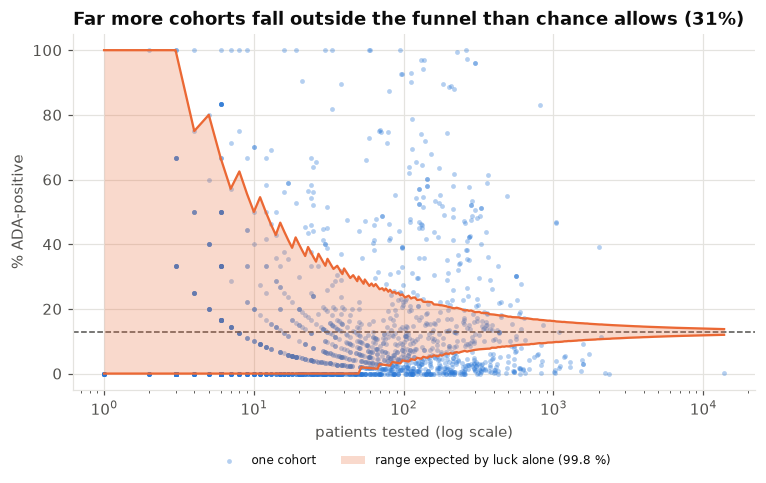

dispersion ratio (≈1 means 'just luck'; ≫1 means overdispersed): 38.8


In [5]:
from scipy.stats import binom
nn = np.unique(np.logspace(0, np.log10(df["n"].max()), 300).round().astype(int))   # patient counts must be whole numbers
lo95, hi95 = binom.ppf(0.025, nn, overall) / nn, binom.ppf(0.975, nn, overall) / nn
lo998, hi998 = binom.ppf(0.001, nn, overall) / nn, binom.ppf(0.999, nn, overall) / nn

outside = (df["y"] < binom.ppf(0.001, df["n"], overall)) | (df["y"] > binom.ppf(0.999, df["n"], overall))
print(f"cohorts outside the 99.8 % funnel: {outside.mean():.1%}  (pure luck would give ≈ 0.2 %)")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(df["n"], df["ada_freq"] * 100, s=10, color=BLUE, alpha=0.35, lw=0, label="one cohort", zorder=2)
ax.fill_between(nn, lo998 * 100, hi998 * 100, color=ORANGE, alpha=0.25, lw=0, zorder=3, label="range expected by luck alone (99.8 %)")
ax.plot(nn, lo998 * 100, color=ORANGE, lw=1.5, zorder=4); ax.plot(nn, hi998 * 100, color=ORANGE, lw=1.5, zorder=4)
ax.axhline(overall * 100, color=INK2, lw=1, ls="--")
ax.set_xscale("log"); ax.set_xlabel("patients tested (log scale)"); ax.set_ylabel("% ADA-positive")
ax.set_title(f"Far more cohorts fall outside the funnel than chance allows ({outside.mean():.0%})")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.savefig(FIG / "eda_funnel_overdispersion.png"); plt.show()

# A simple number for the same idea: Pearson dispersion of an intercept-only Binomial model.
pearson = ((df["y"] - df["n"] * overall) ** 2 / (df["n"] * overall * (1 - overall))).sum() / (len(df) - 1)
print(f"dispersion ratio (≈1 means 'just luck'; ≫1 means overdispersed): {pearson:.1f}")

## 4 · ADA by route of administration

route,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Other,13,4,868,2.0%,1.2%,5.6%,1.9%,3.2%
Ophthalmic,20,5,"2,826",11.0%,2.9%,43.8%,14.2%,16.3%
Intravenous,1082,102,"102,671",12.5%,7.1%,18.1%,11.8%,13.5%
Subcutaneous,639,54,"104,653",13.4%,8.0%,21.4%,14.8%,19.2%


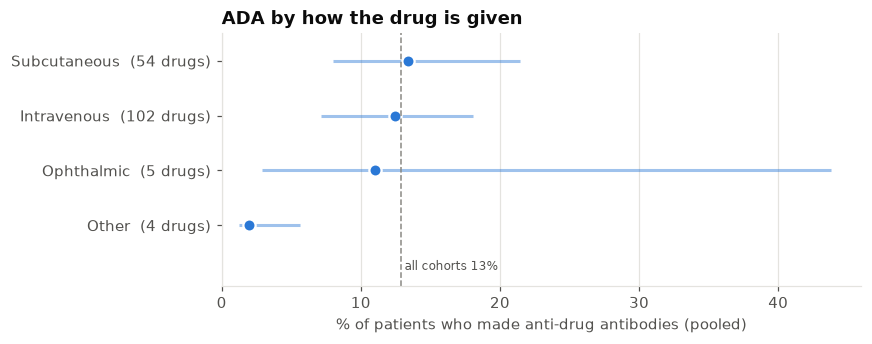

In [6]:
t = summarise(df, "route"); show(t)
dot_plot(t, "route", "ADA by how the drug is given", "eda_route.png")

## 5 · ADA by disease area

indication,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Musculoskeletal,53,7,"8,511",4.4%,1.9%,22.1%,10.2%,7.8%
Healthy Volunteer,47,11,"1,671",5.4%,0.9%,12.0%,16.0%,9.5%
Cardiovascular,75,3,"20,962",9.1%,0.3%,42.3%,16.0%,15.4%
Cancer and neoplasms,797,62,"75,962",10.8%,5.2%,16.7%,10.4%,12.2%
Neurological,109,14,"13,858",12.1%,6.0%,25.2%,8.3%,14.6%
Other,70,22,"6,103",13.1%,2.4%,39.9%,12.3%,13.3%
Unspecified,26,9,"3,069",16.5%,3.7%,61.4%,25.4%,30.8%
Inflammation and autoimmunity,577,46,"80,882",16.8%,10.8%,23.8%,16.2%,18.6%


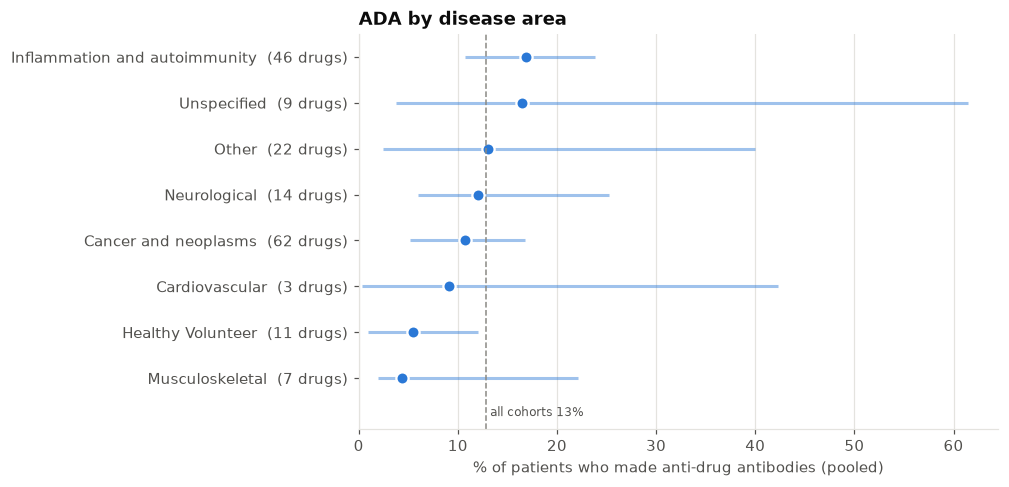

In [7]:
t = summarise(df, "indication"); show(t)
dot_plot(t, "indication", "ADA by disease area", "eda_indication.png")

## 6 · ADA by drug features (ID card)


=== species ===


species,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Other,13,1,471,1.1%,nan%,nan%,0.2%,1.1%
Human,611,47,"88,636",10.0%,4.7%,18.0%,12.7%,16.4%
Humanized,937,67,"106,195",12.9%,7.9%,18.4%,10.8%,12.3%
Chimeric,168,16,"14,616",24.7%,10.9%,34.2%,19.9%,14.4%
Bacterial,25,6,"1,100",89.3%,63.5%,99.0%,53.0%,72.5%


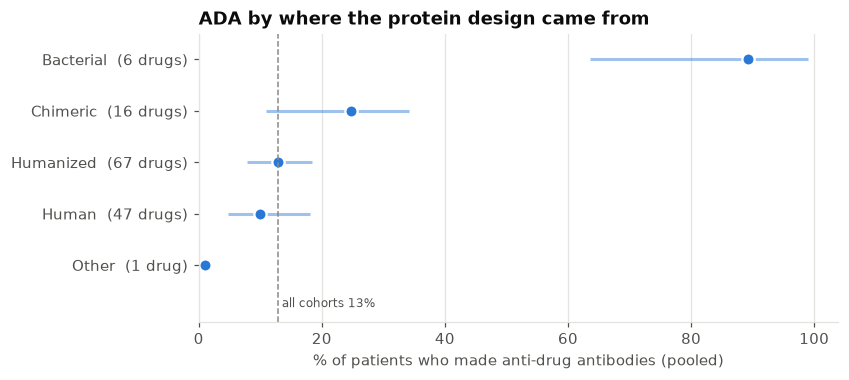


=== modality ===


modality,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Antibody-drug conjugate,52,6,"2,154",9.6%,1.6%,16.4%,4.5%,7.2%
Monoclonal antibody,1622,112,"201,212",12.5%,8.7%,17.3%,12.4%,13.5%
Other,60,15,"7,125",19.4%,7.1%,46.3%,18.6%,25.0%
Immunotoxin,20,4,527,82.5%,67.5%,98.4%,51.3%,83.7%


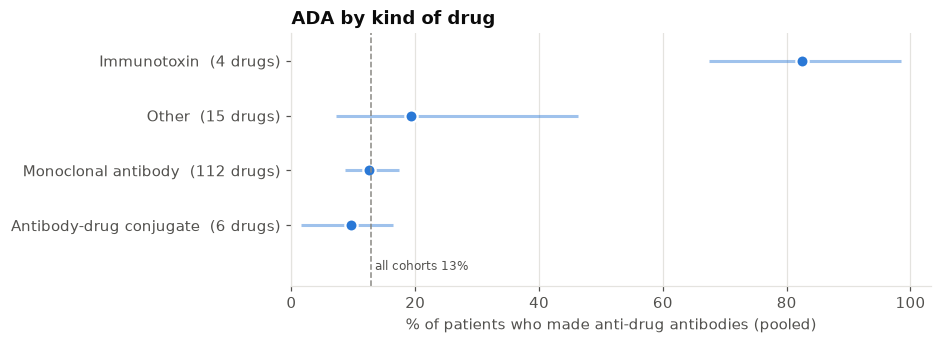


=== backbone ===


backbone,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Human IgG2,307,13,"48,086",7.4%,2.3%,20.4%,11.8%,12.9%
Human IgG4,273,18,"38,049",7.6%,4.1%,11.0%,9.7%,8.5%
Other,51,9,"2,978",12.7%,3.4%,35.2%,9.1%,13.2%
Human IgG1,1068,84,"119,275",16.0%,10.4%,21.4%,12.6%,13.7%
Not applicable,55,13,"2,630",47.8%,16.1%,81.8%,43.3%,51.7%


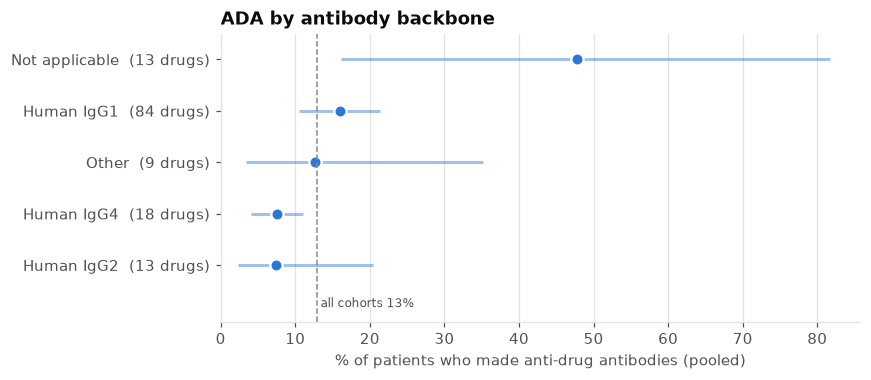


=== expression ===


expression,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Chinese hamster ovary (CHO) cells,1174,83,"152,158",12.0%,7.3%,17.6%,12.0%,12.8%
Murine myeloma cells,352,25,"36,246",12.2%,4.9%,21.2%,10.1%,11.1%
Other,22,5,"2,196",15.0%,4.6%,47.6%,16.1%,19.7%
Undetermined,206,24,"20,418",20.1%,9.0%,44.0%,22.1%,34.5%


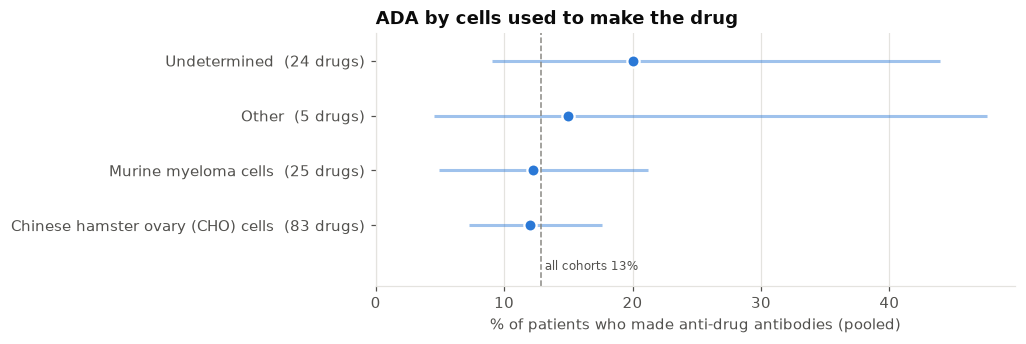

In [8]:
for col, title in [("species", "ADA by where the protein design came from"),
                   ("modality", "ADA by kind of drug"),
                   ("backbone", "ADA by antibody backbone"),
                   ("expression", "ADA by cells used to make the drug")]:
    t = summarise(df, col); print(f"\n=== {col} ==="); show(t)
    dot_plot(t, col, title, f"eda_{col}.png")

## 7 · Co-administered immunosuppressants and other study features

immunosuppressant,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Without,1604,135,"195,728",12.6%,8.3%,17.1%,12.7%,16.6%
With immunosuppressant,150,31,"15,290",16.0%,6.6%,26.0%,14.1%,14.0%


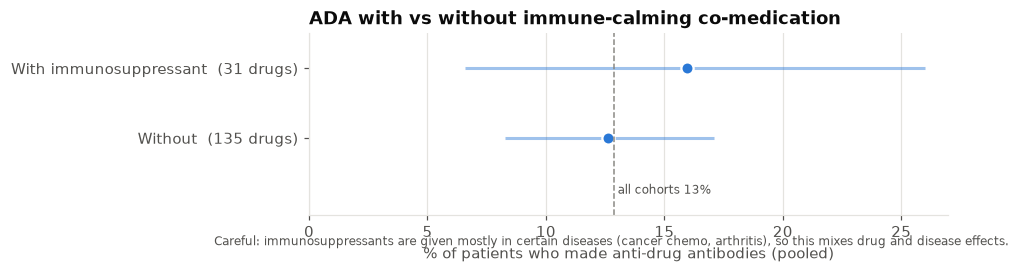

Which disease areas use them?


immunosuppressant,With immunosuppressant,Without
indication,,
Cancer and neoplasms,70,727
Cardiovascular,0,75
Healthy Volunteer,0,47
Inflammation and autoimmunity,79,498
Musculoskeletal,0,53
Neurological,0,109
Other,0,70
Unspecified,1,25



=== blinding ===


blinding,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Other,12,3,406,5.9%,0.0%,100.0%,25.0%,33.3%
Open Label,872,87,"58,348",10.9%,6.5%,15.6%,10.2%,10.1%
Unknown,185,32,"62,556",11.0%,5.3%,22.2%,22.6%,31.8%
Double,623,84,"83,022",14.7%,10.2%,20.7%,12.9%,13.3%
Triple,62,17,"6,686",25.2%,9.9%,39.5%,19.1%,17.2%



=== randomized ===


randomized,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Not Randomized,383,56,"12,928",7.5%,5.4%,10.0%,9.7%,7.2%
Unknown,357,59,"79,404",10.1%,5.6%,17.7%,16.4%,22.9%
Randomized,1014,105,"118,686",15.3%,10.9%,20.2%,12.8%,13.7%



=== comparator ===


comparator,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Unknown,407,68,"82,965",9.7%,5.5%,16.5%,14.4%,19.0%
Placebo/Sham,441,49,"48,258",9.7%,6.1%,14.6%,9.1%,8.7%
Parallel Assignment,529,71,"37,617",13.1%,8.3%,18.2%,11.0%,10.6%
Active controls,377,63,"42,178",22.4%,15.2%,30.8%,18.3%,17.6%



=== source ===


source,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
Clinicaltrials.gov,1474,124,"153,615",11.8%,7.5%,16.8%,11.7%,13.7%
Journal Article,89,18,"26,591",12.4%,6.1%,20.8%,24.9%,20.1%
EU Clinical Trials Register,176,44,"24,473",15.7%,9.2%,24.6%,13.3%,14.3%
Other,15,7,"6,339",30.6%,13.5%,78.3%,48.7%,59.7%


In [9]:
df["immunosuppressant"] = df["co_immunosuppressant"].map({1: "With immunosuppressant", 0: "Without"})
t = summarise(df, "immunosuppressant"); show(t)
dot_plot(t, "immunosuppressant", "ADA with vs without immune-calming co-medication", "eda_immunosuppressant.png",
         note="Careful: immunosuppressants are given mostly in certain diseases (cancer chemo, arthritis), so this mixes drug and disease effects.")
print("Which disease areas use them?")
display(pd.crosstab(df["indication"], df["immunosuppressant"]))

for col in ["blinding", "randomized", "comparator", "source"]:
    print(f"\n=== {col} ==="); show(summarise(df, col))

## 8 · Dose and calendar year

dose_bin,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
< 0.3 mg/kg,257,55,"22,692",15.3%,9.1%,30.4%,16.4%,20.6%
0.3–1,223,49,"32,903",18.8%,9.5%,29.7%,22.0%,19.9%
1–3,390,62,"59,653",12.1%,5.6%,20.9%,12.5%,12.6%
3–10,435,74,"38,065",5.4%,3.8%,7.4%,7.5%,9.3%
> 10,295,41,"22,596",12.8%,4.6%,18.7%,9.1%,9.9%
Unknown,154,42,"35,109",15.2%,7.4%,24.5%,17.1%,17.1%


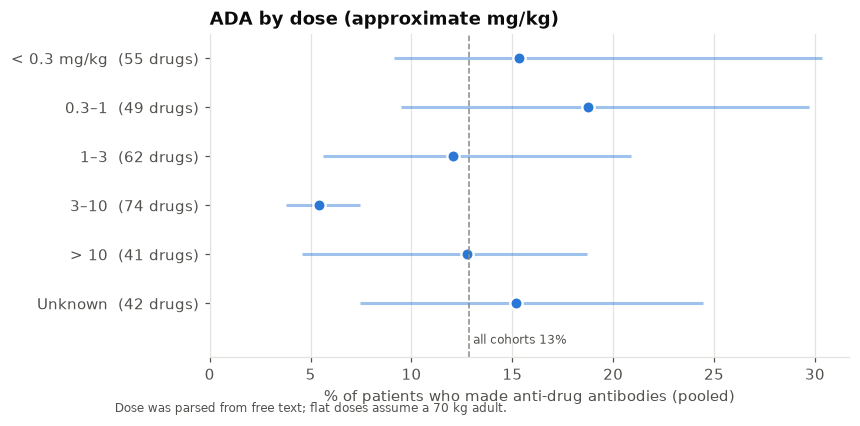

year_bin,cohorts,drugs,patients,pooled,ci_low,ci_high,mean_of_cohorts,drug_balanced
≤2005,44,13,"5,250",16.5%,4.1%,29.9%,19.4%,16.2%
2006–09,233,43,"29,386",4.5%,2.2%,9.1%,8.0%,9.2%
2010–12,365,53,"32,788",6.9%,4.7%,9.9%,9.4%,11.9%
2013–15,582,74,"86,440",14.6%,8.2%,23.0%,15.1%,16.0%
2016–18,436,74,"49,132",14.3%,8.1%,20.8%,11.8%,14.1%
2019+,80,37,"6,670",33.8%,16.8%,48.9%,20.5%,20.4%


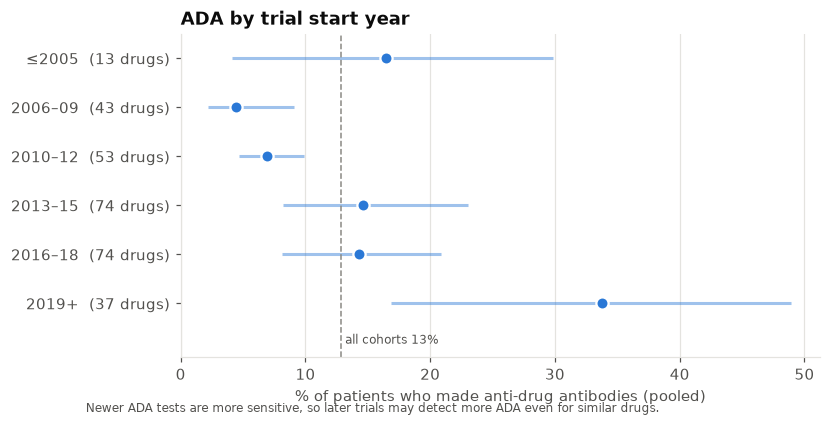

In [10]:
df["dose_bin"] = pd.cut(df["dose_mgkg"], [0, 0.3, 1, 3, 10, np.inf],
                        labels=["< 0.3 mg/kg", "0.3–1", "1–3", "3–10", "> 10"], include_lowest=True)
df["dose_bin"] = df["dose_bin"].cat.add_categories("Unknown").fillna("Unknown")
t = summarise(df, "dose_bin"); t = t.set_index("dose_bin").loc[["< 0.3 mg/kg", "0.3–1", "1–3", "3–10", "> 10", "Unknown"]].reset_index()
show(t)
dot_plot(t.iloc[::-1], "dose_bin", "ADA by dose (approximate mg/kg)", "eda_dose.png",
         note="Dose was parsed from free text; flat doses assume a 70 kg adult.")

df["year_bin"] = pd.cut(df["start_year"], [1990, 2005, 2009, 2012, 2015, 2018, 2025],
                        labels=["≤2005", "2006–09", "2010–12", "2013–15", "2016–18", "2019+"])
t = summarise(df.dropna(subset=["year_bin"]), "year_bin")
t = t.set_index("year_bin").loc[["≤2005", "2006–09", "2010–12", "2013–15", "2016–18", "2019+"]].reset_index()
show(t)
dot_plot(t.iloc[::-1], "year_bin", "ADA by trial start year", "eda_year.png",
         note="Newer ADA tests are more sensitive, so later trials may detect more ADA even for similar drugs.")

## 9 · Do a few drugs dominate?

If one drug supplies a big share of cohorts, a random train/test split would let the model "recognise" that drug.
That's why we will use **grouped cross-validation by drug**.

top 1 drug = 5% of cohorts | top 10 drugs = 33% of cohorts, 36% of patients | drugs with only 1–2 cohorts: 31


Therapeutic Assessed for ADA ID,drug_name,cohorts,patients,y,pooled
PR_0119,Durvalumab,92,"9,305",334,3.6%
PR_0048,Atezolizumab,76,"14,588",3939,27.0%
PR_0052,Avelumab,67,"9,912",897,9.0%
PR_0335,Tanezumab,63,"8,842",571,6.5%
PR_0003,Adalimumab,55,"9,072",2935,32.4%
PR_0177,Infliximab,54,"5,784",2079,35.9%
PR_0306,Rituximab,47,"4,005",440,11.0%
PR_0238,Nivolumab,44,"5,741",741,12.9%
PR_0216,Ixekizumab,44,"6,414",791,12.3%
PR_0293,Ramucirumab,42,"2,826",90,3.2%


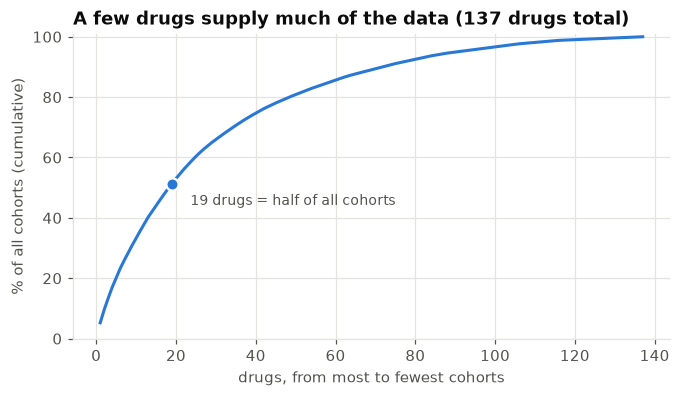

In [11]:
per_drug = (df.groupby([DRUG, "drug_name"]).agg(cohorts=("n", "size"), patients=("n", "sum"), y=("y", "sum"))
              .sort_values("cohorts", ascending=False).reset_index())
per_drug["pooled"] = per_drug["y"] / per_drug["patients"]
top = per_drug.head(10)
print(f"top 1 drug = {per_drug['cohorts'].iloc[0] / len(df):.0%} of cohorts | top 10 drugs = {top['cohorts'].sum() / len(df):.0%} of cohorts, "
      f"{top['patients'].sum() / df['n'].sum():.0%} of patients | drugs with only 1–2 cohorts: {(per_drug['cohorts'] <= 2).sum()}")
display(top.style.format({"pooled": "{:.1%}", "patients": "{:,.0f}"}).hide(axis="index"))

# Cumulative share: how quickly do the biggest drugs eat up the data?
cum = per_drug["cohorts"].cumsum() / len(df)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, len(cum) + 1), cum * 100, color=BLUE, lw=2)
k = int((cum < 0.5).sum()) + 1
ax.plot(k, cum.iloc[k - 1] * 100, "o", color=BLUE, ms=8, mec="white", mew=1.5)
ax.annotate(f"{k} drugs = half of all cohorts", (k, cum.iloc[k - 1] * 100), xytext=(12, -14), textcoords="offset points", color=INK2, fontsize=9)
ax.set_xlabel("drugs, from most to fewest cohorts"); ax.set_ylabel("% of all cohorts (cumulative)")
ax.set_title(f"A few drugs supply much of the data ({len(per_drug)} drugs total)"); ax.set_ylim(0, 101)
fig.savefig(FIG / "eda_drug_concentration.png"); plt.show()

## 10 · How different are drugs from each other?

If ADA mostly depends on *which drug* it is, the between-drug spread will be large. That is what the models need to explain.

drugs with ≥ 200 patients: 96 | their pooled ADA ranges from 0.0% to 99.8%; median 6.1%


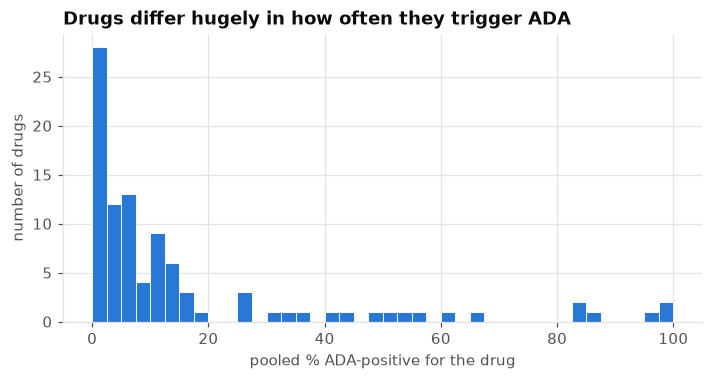

In [12]:
big = per_drug[per_drug["patients"] >= 200].copy()
print(f"drugs with ≥ 200 patients: {len(big)} | their pooled ADA ranges from {big['pooled'].min():.1%} to {big['pooled'].max():.1%}; "
      f"median {big['pooled'].median():.1%}")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(big["pooled"] * 100, bins=np.arange(0, 102, 2.5), color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_xlabel("pooled % ADA-positive for the drug"); ax.set_ylabel("number of drugs")
ax.set_title("Drugs differ hugely in how often they trigger ADA")
fig.savefig(FIG / "eda_between_drug_spread.png"); plt.show()

## 11 · Day 3 findings (write-up)

**What the pictures tell us** (pooled % with drug-bootstrap 95 % intervals; numbers from the cells above)

1. **Many zeros, but mostly from small cohorts.** 35 % of cohorts have 0 % ADA. That's 68 % of cohorts with ≤ 10 patients but only 3 % of cohorts with > 500. Much of the "spike at zero" is small-sample luck, so **weighting by n** matters.
2. **Strong overdispersion.** 31 % of cohorts fall outside the 99.8 % "luck only" funnel (≈ 0.2 % expected). The dispersion ratio is ≈ 39 (1 = pure luck). Cohorts really differ beyond chance, so a plain Binomial model will be over-confident. We need the **Beta-Binomial** and must check GLM dispersion on Day 5.
3. **Which drug it is matters most.** Among drugs with ≥ 200 patients, pooled ADA ranges from **0 % to ≈ 100 %** (median ≈ 6 %). The top 10 drugs supply 33 % of cohorts, so **grouped CV by drug** is essential.
4. **"Foreignness" of the protein is the clearest signal:** bacterial-derived ≈ 89 % (6 drugs), chimeric ≈ 25 %, humanized ≈ 13 %, fully human ≈ 10 %. Immunotoxins (bacterial toxin parts) ≈ 83 %. This matches the biology: the less human the protein looks, the more the immune system reacts. Note that human vs humanized intervals overlap.
5. **Disease area:** inflammation/autoimmunity ≈ 17 % vs cancer ≈ 11 %. This is plausible because cancer patients' immune systems are often suppressed by disease or chemotherapy. The intervals overlap, so it's a hint, not proof.
6. **Route:** subcutaneous ≈ 13 % vs intravenous ≈ 13 % pooled (drug-balanced 19 % vs 14 %). The intervals overlap heavily, so there's **no clear route effect in raw data**. The models will tell us whether one appears after adjusting for drug type.
7. **Confounding warning: immunosuppressant co-medication.** Raw pooled ADA is *higher* with immunosuppressants (16 % vs 13 %), the opposite of biological expectation. But they are used almost only in autoimmune and cancer trials, and the drug-balanced view reverses the direction (14 % vs 17 %). Raw comparisons mix up drug and disease effects; only the multi-feature models can separate them.
8. **Dose:** not a straight line. 3–10 mg/kg has the lowest ADA (≈ 5 %, interval 4–7 %). This could fit "high-dose tolerance", but it is also where many cancer antibodies sit, so we treat it as a hypothesis.
9. **Calendar year:** 2006–2012 trials ≈ 5–7 % vs 2019+ ≈ 34 %. This is consistent with **more sensitive ADA tests** over time, so `start_year` is a useful control variable rather than a biological effect.
10. **Study design:** active-controlled trials ≈ 22 %. This is likely because many are biosimilar trials of high-ADA drugs (adalimumab ≈ 32 %, infliximab ≈ 36 %). This is again the drug, not the design.

**Take-aways for modelling:** weight by n; expect overdispersion (Beta-Binomial); group CV by drug; include drug-origin features, disease area, year and immunosuppressant use *together* so their effects can be separated; describe everything as **associations**.